In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq
from scipy.signal import butter, filtfilt
from scipy.signal import TransferFunction, lsim
from scipy.optimize import minimize

In [2]:
# Datos
data= pd.read_csv("signals.csv")
data.head()

,u,u_r,y_s1,y_s2,t
0,1.000000,1.000000,0.000000e+00,0.000000e+00,0.00
1,1.139468,1.727253,8.076038e-09,6.730189e-09,0.01
2,1.185334,0.234277,2.906984e-07,2.422827e-07,0.02
3,1.150999,2.102055,7.754828e-06,6.467055e-06,0.03
4,1.057618,0.469833,1.997329e-05,1.666384e-05,0.04


In [3]:
t = np.array(data.t)
u = np.array(data.u_r)
y_s1 = np.array(data.y_s1)
y_s2 = np.array(data.y_s2)
print(len(t))
print(len(u))
print(len(y_s1))
print(len(y_s2))

2001
2001
2001
2001


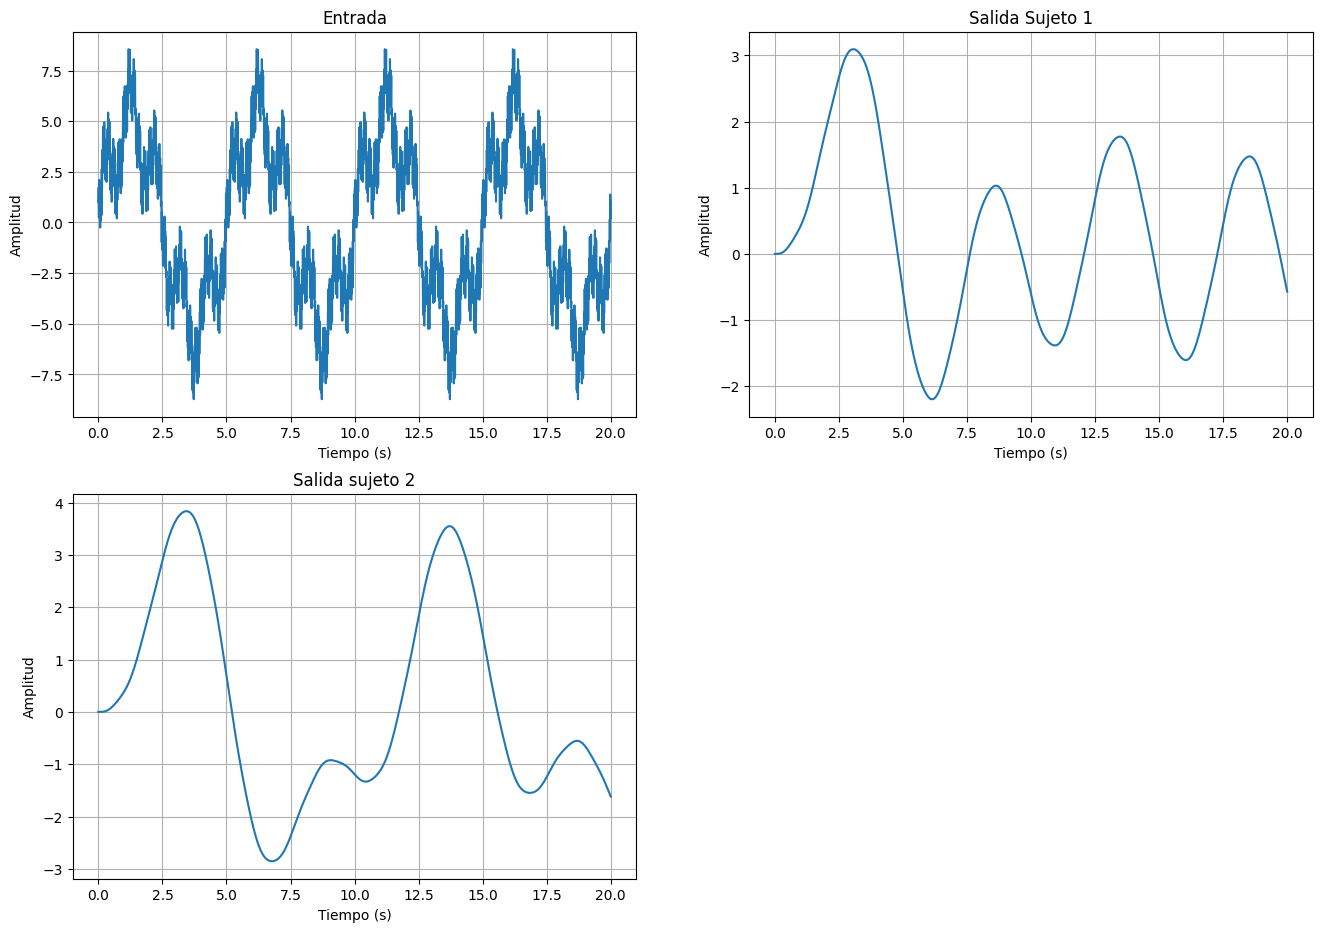

In [4]:
plt.figure(figsize=(16,17))

# Entrada
plt.subplot(321)
plt.plot(t, u)
plt.title("Entrada")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.grid()

plt.subplot(322)
plt.plot(t, y_s1)
plt.title("Salida Sujeto 1")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.grid()

plt.subplot(323)
plt.plot(t, y_s2)
plt.title("Salida sujeto 2")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.grid()

(0.0, 50.0)

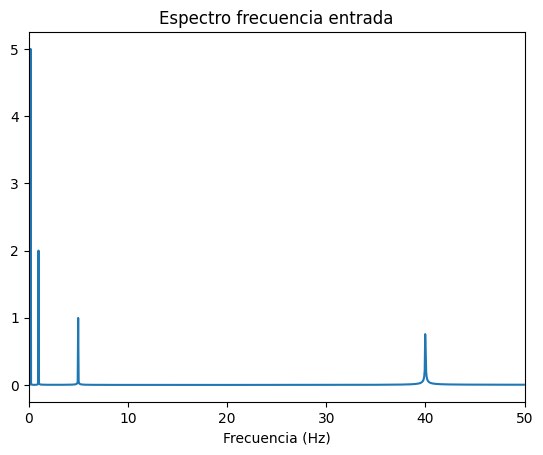

In [13]:
Nu =len(u)
ts= np.mean(np.diff(t))
yfu = fft(u)
xfu = fftfreq(Nu, ts)[:Nu//2]
plt.plot(xfu, 2.0/ Nu*np.abs(yfu[0:Nu//2]))
plt.title("Espectro frecuencia entrada")
plt.xlabel("Frecuencia (Hz)")
plt.xlim(0,50)

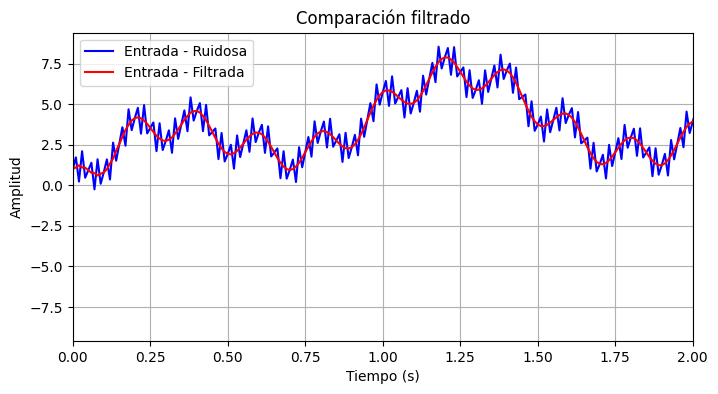

In [19]:
# Filtro
fs = 1/ts
b,a = butter(3,[38,42], btype='stop', fs=fs)
u_filt = filtfilt(b, a, u)

plt.figure(figsize=(8,4))
plt.plot(t, u, 'b', label='Entrada - Ruidosa')
plt.plot(t, u_filt, 'r', label='Entrada - Filtrada')
plt.title("Comparación filtrado")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.legend()
plt.grid()
plt.xlim(0, 2)
plt.show()

In [56]:
def fn_sys(params, t, u):
    A = params[0]
    B = params[1]   
    C = params[2]

    den = [A*B, B*C, 1]
    num = [1]

    system_u = TransferFunction(num, den)
    _, y_pred, _ = lsim(system_u, U=u, T=t)

    return y_pred


def fn_coste(theta):
    global t, u_filt, y_s2
    # Sistema
    den = [theta[0], theta[1], 1]
    num = [1] 
    # Construcción del sistema
    system = TransferFunction(num, den)
    # Simulación
    _, ypred, _ = lsim(system, U= u_filt, T=t)
    # Cálculo del error cuadrático (RMSE)
    e = y_s2 - ypred
    J = np.sum(e**2)

    return J

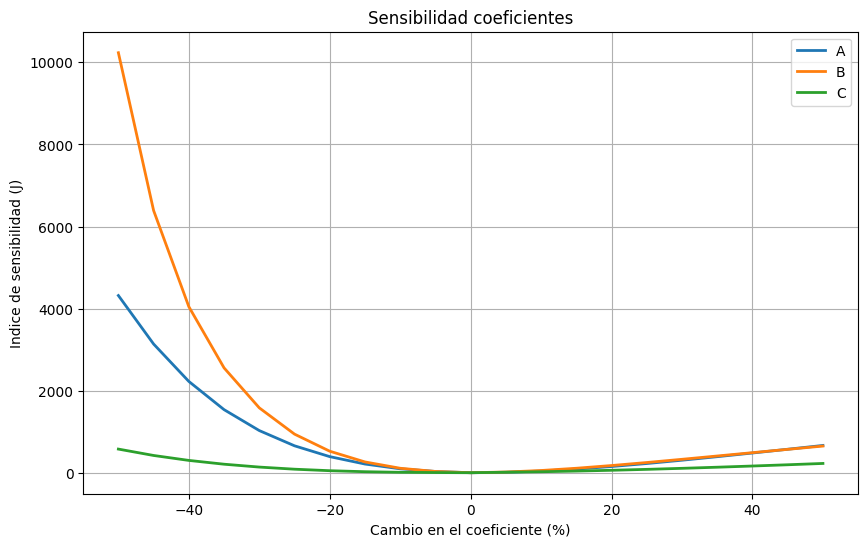

In [57]:
# Sensibilidad
pararef = np.array([5, 0.5, 2])
Np = len(pararef)
step = 5
para_change = np.arange(-50, 51, step)
num_steps = int(2*(50/step)+1)

J = np.zeros((num_steps, Np))

for i in range(Np):
    for k in range(num_steps):  
        para = pararef.copy()
        para[i] = pararef[i] * (1 + para_change[k] / 100)
        if para_change[k] == 0:
            J[k, i] = 0 
        else:
            y_pred = fn_sys(para, t, u_filt)
            e = y_pred - y_s1
            J[k, i] = np.sum(e**2)

# Gráfica
plt.figure(figsize=(10, 6))
labels = ['A','B','C']
for i in range(Np):
    plt.plot(para_change, J[:, i], label=labels[i], linewidth=2)
plt.xlabel('Cambio en el coeficiente (%)')
plt.ylabel('Indice de sensibilidad (J)')
plt.title('Sensibilidad coeficientes')
plt.legend()
plt.grid(True)
plt.show()

In [58]:
# Optimización
# Semilla
theta_init = np.array([100, 100])
res = minimize(fn_coste, theta_init, method='Nelder-Mead')
# Resultados
print('\nValores de theta obtenidos:')
print(res.x)
print('\nResultado completo del optimizador:')
print(res)


Valores de theta obtenidos:
[3.01553087 0.14619546]

Resultado completo del optimizador:
       message: Optimization terminated successfully.
       success: True
        status: 0
           fun: 4.095462945966746
             x: [ 3.016e+00  1.462e-01]
           nit: 63
          nfev: 119
 final_simplex: (array([[ 3.016e+00,  1.462e-01],
                       [ 3.016e+00,  1.463e-01],
                       [ 3.016e+00,  1.462e-01]]), array([ 4.095e+00,  4.095e+00,  4.095e+00]))


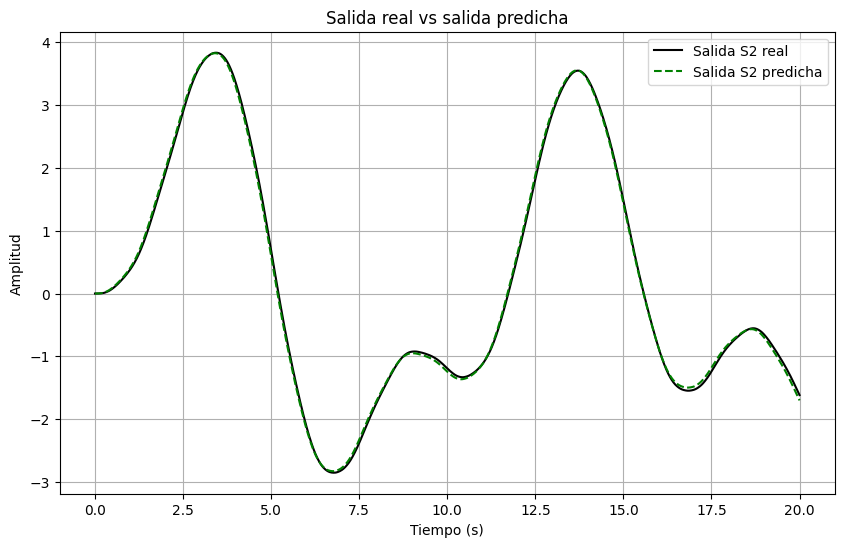

In [63]:
den = [res.x[0], res.x[1], 1]
num = [1]
system = TransferFunction(num, den)
_, ypred_s, _ = lsim(system, U=u_filt, T=t)


# Graficar
plt.figure(figsize=(10,6))
plt.plot(t, y_s2, 'k', label='Salida S2 real')
plt.plot(t, ypred_s, color='green', label='Salida S2 predicha', linestyle='--')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.title('Salida real vs salida predicha')
plt.legend()
plt.grid(True)
plt.show()